# Different Approaches to Defining Neural Networks with Keras and TensorFlow




# Importing Python Libraries 

If you get an error that a library is not installed, most libraries you can stall on a jupyter notebook by creating a new cell and typing:

- *! pip install library_name*


# Note: If not necessary, you are not allowed to change the provided code.

In [1]:
%matplotlib inline 
import tensorflow as tf
from tensorflow.keras.utils import to_categorical # Function to convert labels to one-hot encoding
import pandas as pd  
import numpy as np 
import matplotlib.pyplot as plt 

from sklearn.datasets import load_breast_cancer  # Function for loading the breast_cancer dataset
from sklearn.model_selection import train_test_split # Function for splitting the dataset

# Data exploration

In [2]:
# Load the dataset and return to the defined variable 
dataset = load_breast_cancer()

In [3]:
# Load breast_cancer data into a DataFrame
dframe = pd.DataFrame(dataset.data, columns=dataset.feature_names)
# add "target_label" column to the dataset and name it "label"
dframe['labels'] = dataset.target.astype(int) # Labels are represented as integers
# use of String label
dframe['label_names'] = dframe.labels.replace(dict(enumerate(dataset.target_names)))

In [4]:
# Prints the 5 first rows/samples of the dataset
dframe.head(5)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,labels,label_names
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


In [5]:
# Generates a short description of the dataset (missing values, mean values, etc.)
dframe.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,labels
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


## Train, Validation and Test Sets Split

In [6]:
# Extracting the features and labels from the dataset 
X = np.asarray(dframe[dataset.feature_names])
Y = np.asarray(dframe['labels'])

#######################
#input your code below

# Import the necessary function
from sklearn.model_selection import train_test_split

# Step 1: Split the dataset into training + validation (80%) and test sets (20%)
X_train_val, X_test, Y_train_val, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

# Step 2: Further split the training + validation set into separate training (70%) and validation sets (30%)
X_train, X_val, Y_train, Y_val = train_test_split(X_train_val, Y_train_val, test_size=0.25, random_state=42, stratify=Y_train_val)

# Print the shapes of the resulting datasets
print("Training set shape (X_train, Y_train):", X_train.shape, Y_train.shape)
print("Validation set shape (X_val, Y_val):", X_val.shape, Y_val.shape)
print("Test set shape (X_test, Y_test):", X_test.shape, Y_test.shape)







Training set shape (X_train, Y_train): (341, 30) (341,)
Validation set shape (X_val, Y_val): (114, 30) (114,)
Test set shape (X_test, Y_test): (114, 30) (114,)


## Data Normalization

In [7]:
# min-max data normalization
x_train_min = X_train.min(axis = 0, keepdims = True)
x_train_max = X_train.max(axis = 0, keepdims = True)

X_train = (X_train - x_train_min)/(x_train_max - x_train_min)
X_val = (X_val - x_train_min)/(x_train_max - x_train_min)
X_test = (X_test - x_train_min)/(x_train_max - x_train_min)

## Representing Labels using one-hot-ecoding

In [8]:
k = np.unique(Y).size
Y_oh_train = to_categorical(Y_train, k) 
Y_oh_val = to_categorical(Y_val, k) 
Y_oh_test = to_categorical(Y_test, k)
# Displaying the 5 first elemnts
print('Y_train[:5]:')
print(Y_train[:5])
print('\nY_oh_train[:5]=')
print(Y_oh_train[:5])

Y_train[:5]:
[1 0 1 1 0]

Y_oh_train[:5]=
[[0. 1.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [1. 0.]]


In [9]:
print( "Size of X_train : " , X_train.shape)
print( "Size of X_val : " , X_val.shape)
print( "Size of X_test : " , X_test.shape)

Size of X_train :  (341, 30)
Size of X_val :  (114, 30)
Size of X_test :  (114, 30)


## Different Approaches for Defining Neural Networks

### 1. The Sequential API

In [10]:
#######################
#input your code below
# model 1

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Initialize the model
model1 = Sequential()

# Input Layer + First Hidden Layer
model1.add(Dense(units=64, activation='relu', input_shape=(X_train.shape[1],)))

# Second Hidden Layer
model1.add(Dense(units=32, activation='relu'))

# Optional Dropout Layer to reduce overfitting
model1.add(Dropout(rate=0.5))

# Output Layer for binary classification using one-hot encoded labels
model1.add(Dense(units=2, activation='softmax'))  # 2 units for binary classification (one-hot encoded labels)

# Compile the model
model1.compile(optimizer='adam', 
                loss='categorical_crossentropy',  # Appropriate for one-hot encoded labels
                metrics=['accuracy'])

# Summary of the model
model1.summary()


C:\Users\HSH\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,130 (16.13 KB)

 Trainable params: 4,130 (16.13 KB)

 Non-trainable params: 0 (0.00 B)

### 2. The Functional API

In [11]:
#######################
#input your code below
# model 2

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout

# Define the input layer
input_layer = Input(shape=(X_train.shape[1],))  # Input shape matches the number of features

# First Hidden Layer
hidden_layer_1 = Dense(units=64, activation='relu')(input_layer)

# Second Hidden Layer
hidden_layer_2 = Dense(units=32, activation='relu')(hidden_layer_1)

# Optional Dropout Layer
dropout_layer = Dropout(rate=0.5)(hidden_layer_2)

# Output Layer
output_layer = Dense(units=2, activation='softmax')(dropout_layer)  # 2 units for binary classification

# Create the model
model2 = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model2.compile(optimizer='adam', 
                 loss='categorical_crossentropy', 
                 metrics=['accuracy'])

# Summary of the model
model2.summary()





Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,130 (16.13 KB)

 Trainable params: 4,130 (16.13 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Model Subclassing 

In [12]:
#input your code below
# model 3

import tensorflow as tf
from tensorflow.keras.layers import Dense, Dropout

# Define a custom model class
class Model3(tf.keras.Model):
    def __init__(self):
        super(Model3, self).__init__()
        # Define layers in the constructor
        self.dense1 = Dense(units=64, activation='relu')
        self.dense2 = Dense(units=32, activation='relu')
        self.dropout = Dropout(rate=0.5)
        self.output_layer = Dense(units=2, activation='softmax')

    def call(self, inputs):
        # Define the forward pass
        x = self.dense1(inputs)
        x = self.dense2(x)
        x = self.dropout(x)
        return self.output_layer(x)

# Create an instance of the model
model3 = Model3()

# Compile the model
model3.compile(optimizer='adam', 
                 loss='categorical_crossentropy', 
                 metrics=['accuracy'])

# Summary of the model
model3.build(input_shape=(None, X_train.shape[1]))  # Specify input shape for summary
model3.summary()









C:\Users\HSH\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\layer.py:391: UserWarning: `build()` was called on layer 'model3', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "model3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Training and Testing the Model

In [13]:
model1.compile(optimizer='adam',loss='categorical_crossentropy', metrics=['accuracy']) # compiling the model 1
#model2.compile(optimizer='adam',loss='categorical_crossentropy', metrics=['accuracy']) # compiling the model 2
#model3.compile(optimizer='adam',loss='categorical_crossentropy', metrics=['accuracy']) # compiling the model 3

In [14]:
# training the model 
history = model1.fit(X_train, Y_oh_train, validation_data=(X_val,Y_oh_val),batch_size= 64, epochs= 300)

Epoch 1/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.4500 - loss: 0.7298 - val_accuracy: 0.7456 - val_loss: 0.6610
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6678 - loss: 0.6436 - val_accuracy: 0.8333 - val_loss: 0.6285
Epoch 3/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7169 - loss: 0.6122 - val_accuracy: 0.8684 - val_loss: 0.5978
Epoch 4/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7086 - loss: 0.6169 - val_accuracy: 0.8772 - val_loss: 0.5672
Epoch 5/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7622 - loss: 0.5846 - val_accuracy: 0.8947 - val_loss: 0.5358
Epoch 6/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8292 - loss: 0.5397 - val_accuracy: 0.9035 - val_loss: 0.5010
Epoch 7/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8221 - loss: 0.5007 - val_accuracy: 0.9123 - val_loss: 0.4618
Epoch 8/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8168 - loss: 0.4964 - val_accuracy: 0.9211 - val_loss:

Test loss (cross-entropy and accuracy): [0.10356957465410233, 0.9385964870452881]

Layer 0
Bias:
 [ 0.12042386 -0.02594551 -0.03204334 -0.01197588  0.15252794  0.11729944
  0.14124694 -0.23566157  0.20877396 -0.02163197 -0.15300629 -0.16245274
  0.         -0.16319163 -0.14760491  0.1742377   0.         -0.15097138
  0.08513071  0.13483413 -0.11746443 -0.09110974 -0.02534314  0.07425429
  0.20822553 -0.17780975  0.20371206 -0.0987732  -0.00809755  0.1794868
 -0.17824636 -0.0662755   0.08054385 -0.13772011  0.21071133 -0.02198255
  0.23567472  0.16565084 -0.01497011 -0.13365312  0.00769858  0.18728416
 -0.00898024 -0.04968323 -0.12800851  0.2010014  -0.10342123 -0.16092691
  0.17562646  0.10997108  0.         -0.17430377  0.16701838  0.
  0.18110053  0.18934672 -0.11182791  0.18168807  0.07375428 -0.13619612
 -0.0122602   0.20518722  0.14037775 -0.1369843 ]
W:
 [[ 0.03735149  0.2074389  -0.2545122  ...  0.03005947  0.02053208
   0.08355954]
 [ 0.19567439  0.0711854  -0.04277206 ... -0.0

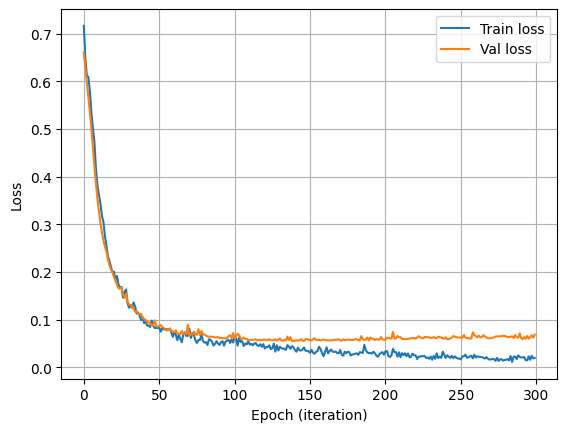

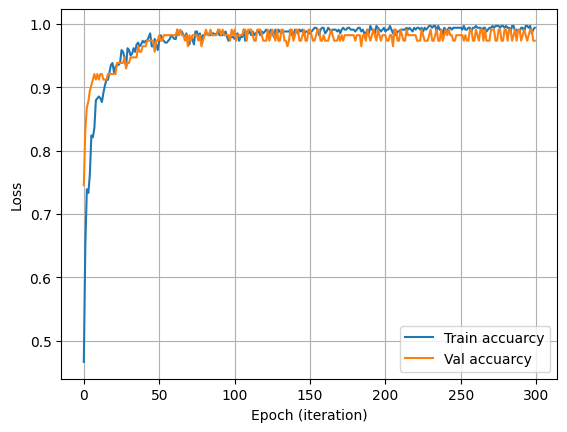

In [15]:
loss = model1.evaluate(X_test, Y_oh_test, verbose=0)
print('Test loss (cross-entropy and accuracy):',loss)
print()
W = model1.get_weights()
for ii in range(len(W)//2):
    print("Layer %d" %ii)
    print('Bias:\n', W[2*ii + 1])
    print('W:\n', W[2*ii])
    print()

plt.plot(history.history['loss'], label = "Train loss")
plt.plot(history.history['val_loss'], label = "Val loss")
plt.xlabel("Epoch (iteration)")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


plt.plot(history.history['accuracy'], label = "Train accuarcy")
plt.plot(history.history['val_accuracy'], label = "Val accuarcy")
plt.xlabel("Epoch (iteration)")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# References for creating this jupyter notebook 

1) https://keras.io/guides/functional_api/

2) https://keras.io/api/models/sequential/

3) https://keras.io/api/models/

4) https://towardsdatascience.com/3-ways-to-create-a-machine-learning-model-with-keras-and-tensorflow-2-0-de09323af4d3